<a href="https://colab.research.google.com/github/izauratm/DeteccaoAnomaliasTransacoesPython/blob/main/deteccao_fraudes_cartao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# dataset link oficial
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

print(f"Dimensões do dataset: {df.shape}")
display(df.head())

# verificando a proporção das classes
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

print("Contagem de classes:")
print(class_counts)
print("\nPercentual de classes:")
print(class_pct)

Dimensões do dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Contagem de classes:
Class
0    284315
1       492
Name: count, dtype: int64

Percentual de classes:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# reduzir o impacto de valores extremos
df['Log_Amount'] = np.log1p(df['Amount'])

X = df.drop(columns=['Class', 'Time', 'Amount'])
y = df['Class']

# divisão: treino e teste com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# padronizando dados
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
print(f"Formato de X_train: {X_train.shape}")
print(f"Formato de X_test: {X_test.shape}")
print(f"Proporção de fraudes no treino:\n{y_train.value_counts(normalize=True) * 100}")

Formato de X_train: (227845, 29)
Formato de X_test: (56962, 29)
Proporção de fraudes no treino:
Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, precision_recall_curve
import numpy as np

print("Treinando o modelo de Regressão Logística...")
lr_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Relatório com Limiar Padrão (0.5) ---")
print(classification_report(y_test, (y_pred_proba_lr >= 0.5).astype(int)))

precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba_lr)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]

print(f"\nMelhor limiar de decisão encontrado: {best_threshold:.4f}")

y_pred_custom = (y_pred_proba_lr >= best_threshold).astype(int)
print(f"\n--- Relatório com Limiar Otimizado ({best_threshold:.4f}) ---")
print(classification_report(y_test, y_pred_custom))

Treinando o modelo de Regressão Logística...

--- Relatório com Limiar Padrão (0.5) ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962


Melhor limiar de decisão encontrado: 1.0000

--- Relatório com Limiar Otimizado (1.0000) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.82      0.82        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



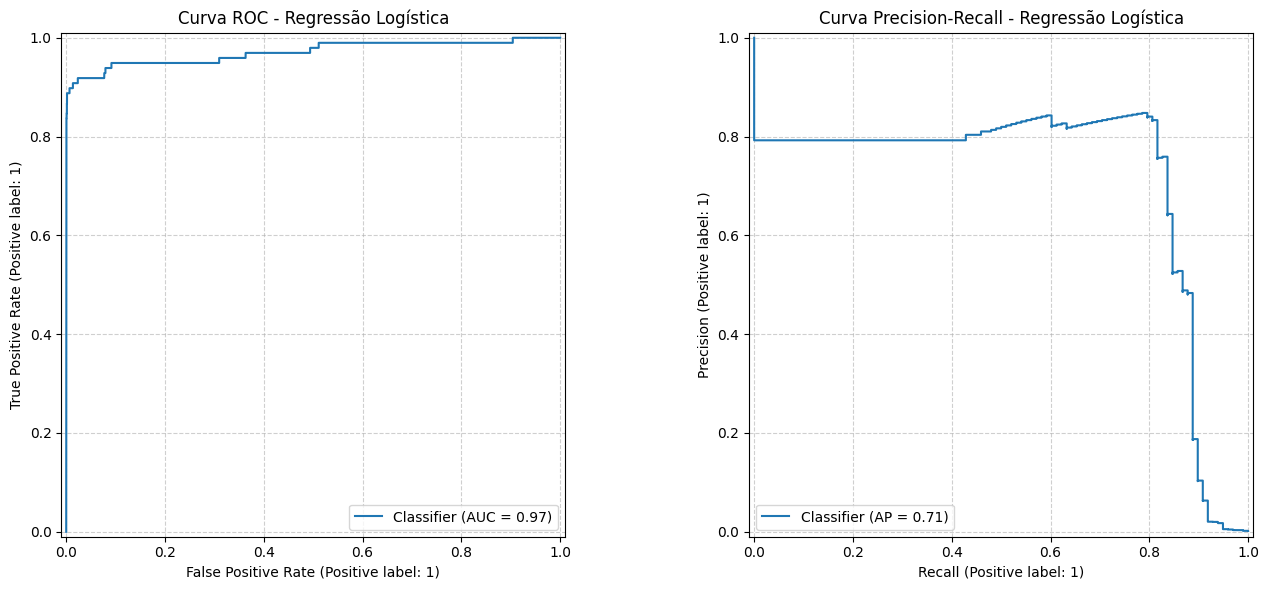

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# curva ROC
RocCurveDisplay.from_predictions(y_test, y_pred_proba_lr, ax=axes[0])
axes[0].set_title("Curva ROC - Regressão Logística")
axes[0].grid(True, linestyle='--', alpha=0.6)

# curva precision-recal
PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba_lr, ax=axes[1])
axes[1].set_title("Curva Precision-Recall - Regressão Logística")
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Treinando o XGBoost para a explicabilidade com SHAP...
Calculando os valores SHAP...


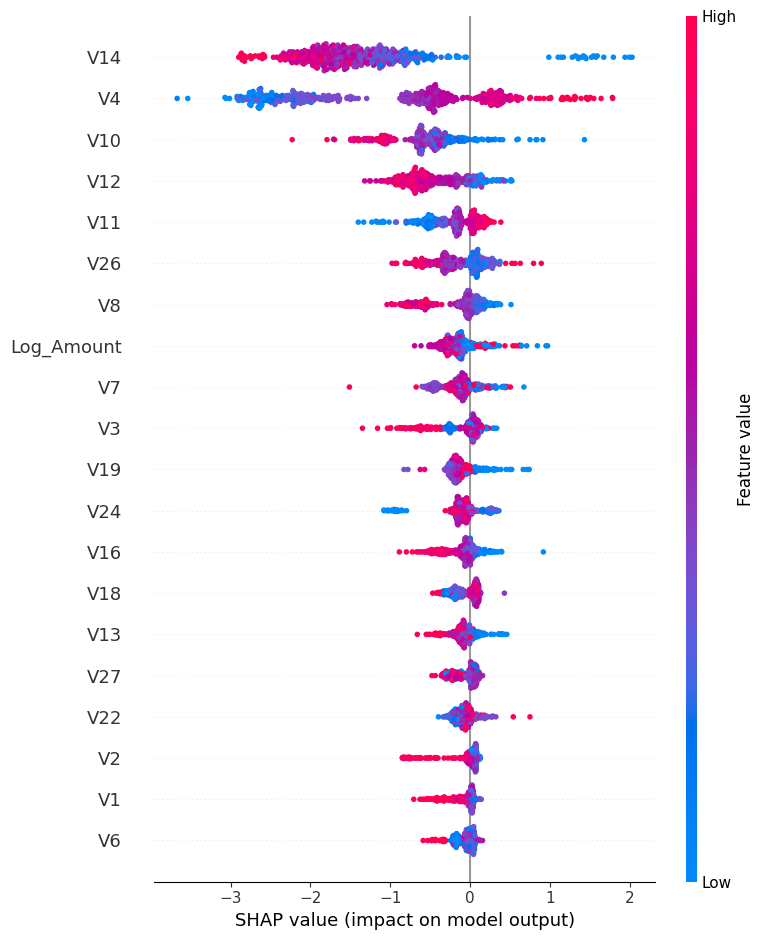

In [9]:
import shap
from xgboost import XGBClassifier

# calculando peso
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

print("Treinando o XGBoost para a explicabilidade com SHAP...")
xgb_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1
)
xgb_model.fit(X_train_scaled, y_train)

# amostragem 500 registros do conjunto de teste
print("Calculando os valores SHAP...")
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_scaled[:500])

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_scaled[:500], feature_names=X.columns)
plt.show()

In [10]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import recall_score

#  Undersampling
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train_scaled, y_train)

# Oversampling com SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Tamanho original do treino: {X_train_scaled.shape}")
print(f"Tamanho após Undersampling: {X_train_under.shape}")
print(f"Tamanho após SMOTE (Oversampling): {X_train_smote.shape}")

Tamanho original do treino: (227845, 29)
Tamanho após Undersampling: (788, 29)
Tamanho após SMOTE (Oversampling): (454902, 29)


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, precision_recall_curve

print("Treinando o Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# ajustando limiar para o Random Forest
precision_rf, recall_rf, thresholds_rf = precision_recall_curve(y_test, y_pred_proba_rf)
f1_rf = 2 * (precision_rf * recall_rf) / (precision_rf + recall_rf + 1e-10)
best_threshold_rf = thresholds_rf[np.argmax(f1_rf)]

print(f"Melhor limiar para o Random Forest: {best_threshold_rf:.4f}")

# avaliação limiar otimizado
y_pred_rf_custom = (y_pred_proba_rf >= best_threshold_rf).astype(int)
print("\n--- Relatório Otimizado - Random Forest ---")
print(classification_report(y_test, y_pred_rf_custom))

Treinando o Random Forest...
Melhor limiar para o Random Forest: 0.2700

--- Relatório Otimizado - Random Forest ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.93      0.83      0.88        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [12]:
from sklearn.metrics import recall_score, precision_score, f1_score

# coleta das métricas de fraude (classe 1)
metrics_summary = {
    "Modelo": [
        "Regressão Logística (Padrão 0.5)",
        "Regressão Logística (Limiar Otimizado)",
        "Random Forest (Limiar Otimizado)"
    ],
    "Recall (Fraude)": [
        recall_score(y_test, (y_pred_proba_lr >= 0.5).astype(int)),
        recall_score(y_test, y_pred_custom),
        recall_score(y_test, y_pred_rf_custom)
    ],
    "Precisão (Fraude)": [
        precision_score(y_test, (y_pred_proba_lr >= 0.5).astype(int), zero_division=0),
        precision_score(y_test, y_pred_custom, zero_division=0),
        precision_score(y_test, y_pred_rf_custom, zero_division=0)
    ]
}

df_comparison = pd.DataFrame(metrics_summary)
print("\n=== TABELA COMPARATIVA DE MODELOS ===")
display(df_comparison)


=== TABELA COMPARATIVA DE MODELOS ===


,Modelo,Recall (Fraude),Precisão (Fraude)
0,Regressão Logística (Padrão 0.5),0.918367,0.057692
1,Regressão Logística (Limiar Otimizado),0.816327,0.833333
2,Random Forest (Limiar Otimizado),0.826531,0.931034
